# Вариант 2:

## Методы:

2. Ньютона-Рафсона
3. Марквардта

## Задания

### 2

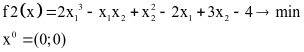
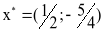

### 5

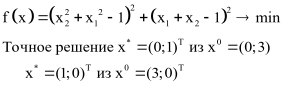

mark

In [1]:
import numpy as np
from scipy.optimize import approx_fprime, minimize_scalar

import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [2]:
def f2(x):
    x = np.asarray(x)
    x1, x2 = x[0], x[1]
    return 2 * x1**3 - x1 * x2 + x2**2 - 2*x1 + 3*x2 - 4

In [3]:
# TODO: get min depends on function

In [4]:
def f5(x):
    x = np.asarray(x)
    x1, x2 = x[0], x[1]
    return (x2**2 + x1**2 - 1)**2 + (x1 + x2 - 1)**2

In [5]:
def gradient(func):
    # вектор частных производных
    return lambda x: approx_fprime(np.asarray(x, dtype=float), func, 1e-6)

In [6]:
def plot3d(f, path, x_star, x_res, bounds=(-2,2,-2,2), title='', num=100, color='viridis'):
    xs, ys = np.linspace(bounds[0], bounds[1], num), np.linspace(bounds[2], bounds[3], num)
    X, Y = np.meshgrid(xs, ys); Z = f([X, Y]); Zp = np.array([f(p) for p in path])
    fig = go.Figure([
        go.Surface(x=X, y=Y, z=Z, opacity=.9, colorscale=color, showscale=False),
        go.Scatter3d(x=path[:,0], y=path[:,1], z=Zp, mode='lines+markers',
                     line=dict(color='blue', width=6), marker=dict(size=3), name='trajectory'),
        go.Scatter3d(x=[x_star[0]], y=[x_star[1]], z=[f(x_star)], mode='markers',
                     marker=dict(size=10, color='red', symbol='diamond'), name='x*'),
        go.Scatter3d(x=[x_res[0]], y=[x_res[1]], z=[f(x_res)], mode='markers', marker=dict(size=10, color='green', symbol='diamond'), name='res'),
    ])
    fig.update_layout(title=title, width=950, height=700,
                      scene=dict(aspectmode='cube', camera=dict(eye=dict(x=1.6,y=-1.6,z=1.0))),
                      margin=dict(l=0,r=0,b=0,t=40))
    fig.show(renderer='iframe')

In [7]:
def plot_contour(f, paths, bounds=(-10, 10, -10, 10), levels=30):
    paths = [paths]

    xmin, xmax, ymin, ymax = bounds
    xs = np.linspace(xmin, xmax, 300)
    ys = np.linspace(ymin, ymax, 300)
    X, Y = np.meshgrid(xs, ys)
    Z = np.array([[f(np.array([x, y])) for x in xs] for y in ys])
    Z = np.sign(Z) * np.log10(np.abs(Z) + 1)

    plt.figure(figsize=(7, 6))
    plt.contour(X, Y, Z, levels=levels, cmap='turbo', linewidths=0.7)

    for path in paths:
        path = np.asarray(path)
        plt.plot(path[:, 0], path[:, 1], '-o', markersize=2, linewidth=1)
        plt.plot(path[0, 0], path[0, 1], 'ks', markersize=8)   
        plt.plot(path[-1, 0], path[-1, 1], 'r*', markersize=14)

    plt.xlim(xmin, xmax)
    plt.ylim(ymin, ymax)
    plt.gca().set_aspect('equal')
    plt.grid(alpha=0.3)
    plt.show()

In [8]:
def hess(grad, x):
    H = approx_fprime(x, grad, 1e-5)
    return H

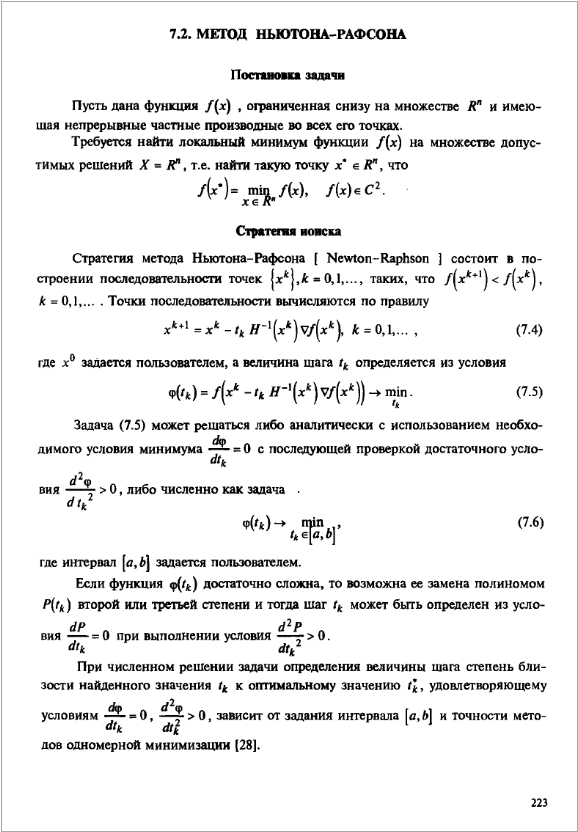
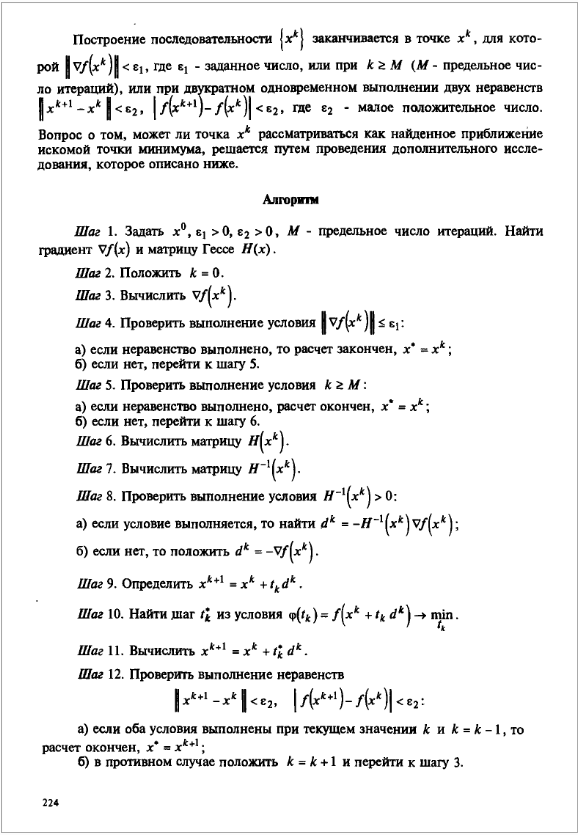
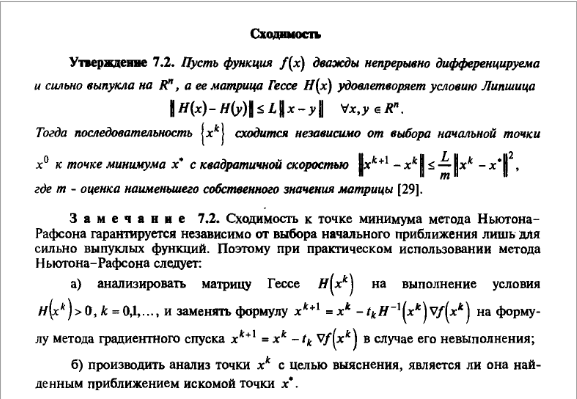

In [9]:
def newton_rafson(f, x0, limit=2000, eps=(1e-5, 1e-5)):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    grad = gradient(f)
    eps1, eps2 = eps[0], eps[1]

    k = 0
    prev = False
    while True:
        g = grad(x)
        if np.linalg.norm(g) <= eps1:
            break
        if k >= limit:
            break

        H = hess(grad, x)
        d = -g
        # If a is detected to be singular, a LinAlgError is raised. 
        # If a is ill-conditioned, a LinAlgError may or may not be raised, and results may be inaccurate due to floating-point errors.
        try:
            H_inv = np.linalg.inv(H)
            if np.all(np.real(np.linalg.eigvals(H_inv) > 0)):
                d = -np.dot(H_inv, g)
        except np.linalg.LinAlgError:
            pass
            
        t = minimize_scalar(lambda t: f(x+t*d), bounds=(0.0, 1.0), method='bounded').x
        x_new = x + t * d
        path.append(x_new.copy())

        conv = (np.linalg.norm(x_new - x) < eps2) and (abs(f(x_new) - f(x)) < eps2)
        if conv and prev:
            x = x_new
            break
        x = x_new
        prev = conv
        k+=1
    return x, f(x), np.array(path)

In [10]:
x_f2, f_f2, path_f2 = newton_rafson(f=f2, x0=[0.0, 0.0], limit=100)
plot3d(f2, path_f2, [1/2,-5/4], x_f2, title="Ньютон-Рафсон на f2", bounds=(-20, 20, -20, 20))
print(f'{path_f2}')

[[ 0.          0.        ]
 [ 0.58906606 -0.88359938]
 [ 0.39306575 -1.30346568]
 [ 0.33841286 -1.33079164]
 [ 0.33337609 -1.33331245]
 [ 0.33333333 -1.33333383]]


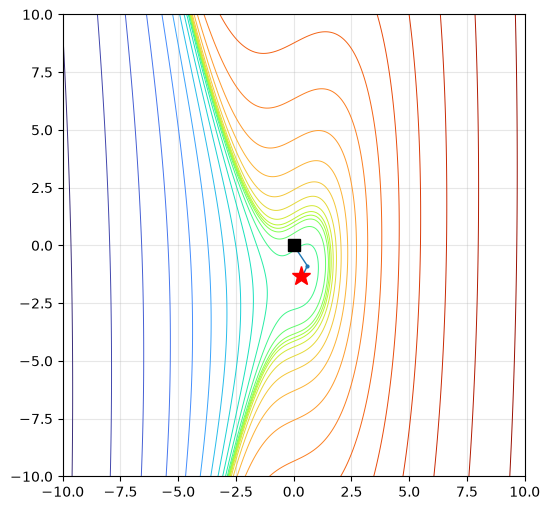

In [11]:
plot_contour(f2, path_f2)

In [12]:
x_f5, f_f5, path_f5 = newton_rafson(f=f5, x0=[0.0, 3.0], limit=100)
plot3d(f5, path_f5, [0,1], x_f5, title="Ньютон-Рафсон на f5", bounds=(-20, 20, -20, 20))
print(f'{path_f5}')

[[ 0.00000000e+00  3.00000000e+00]
 [-6.22389457e-02  2.05779803e+00]
 [-1.03178183e-01  1.47195305e+00]
 [-1.03365451e-01  1.15297487e+00]
 [-5.40491261e-02  1.03014325e+00]
 [-8.80418463e-03  1.00346143e+00]
 [-2.03398628e-04  1.00008369e+00]
 [-5.19656267e-07  9.99999715e-01]]


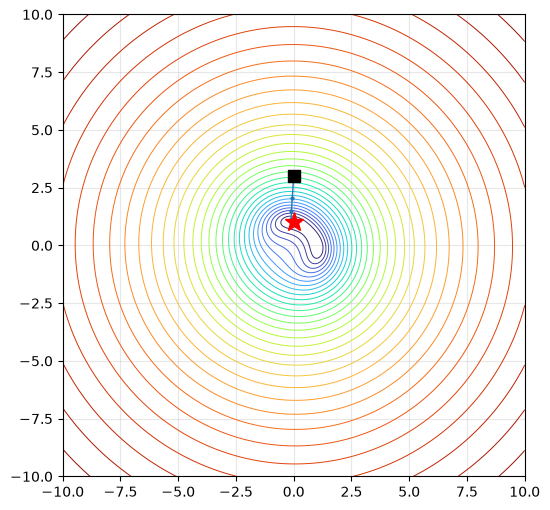

In [13]:
plot_contour(f5, path_f5)

In [14]:
x_f5, f_f5, path_f5 = newton_rafson(f=f5, x0=[3.0, 0.0], limit=100)
plot3d(f5, path_f5, [1,0], x_f5, title="Ньютон-Рафсон на f5", bounds=(-20, 20, -20, 20))
print(f'{path_f5}')

[[ 3.00000000e+00  0.00000000e+00]
 [ 2.05779803e+00 -6.22389457e-02]
 [ 1.47195078e+00 -1.03186437e-01]
 [ 1.15297438e+00 -1.03368529e-01]
 [ 1.03014320e+00 -5.40500704e-02]
 [ 1.00346148e+00 -8.80430429e-03]
 [ 1.00008369e+00 -2.03404639e-04]
 [ 9.99999715e-01 -5.19656664e-07]]


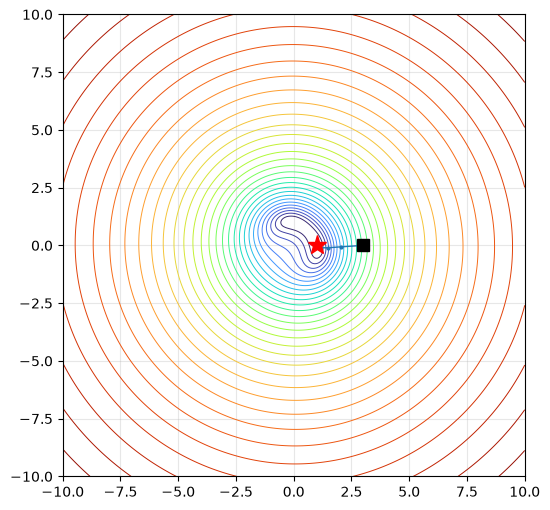

In [15]:
plot_contour(f5, path_f5)

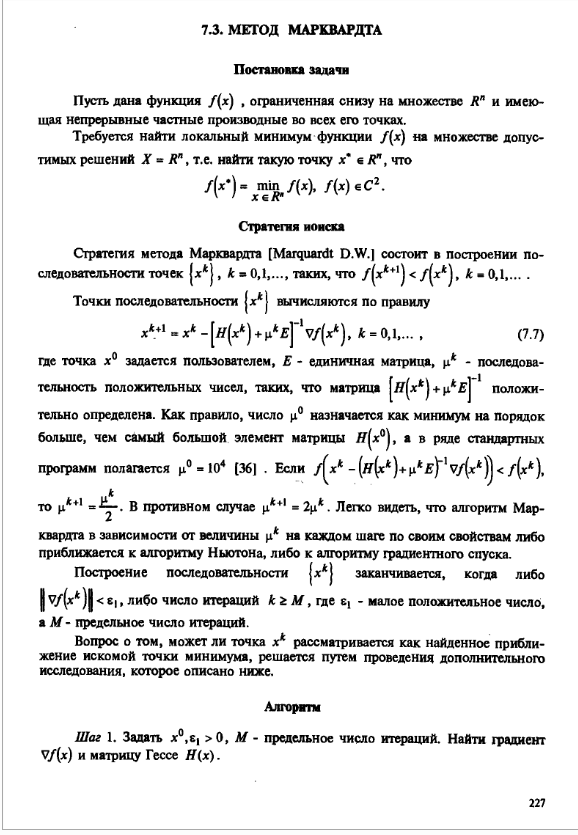
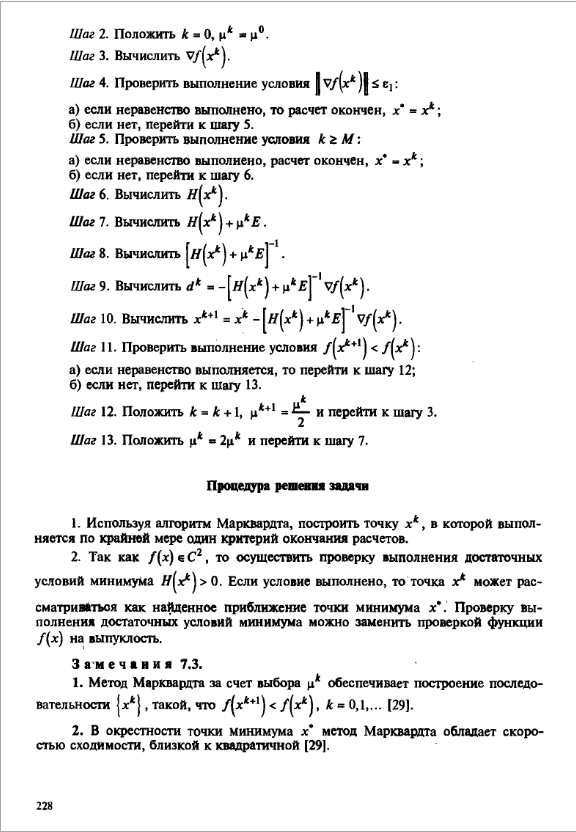


In [16]:
def marq(f, x0, eps1=1e-5, limit=200):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    grad = gradient(f)
    n = len(x)

    k = 0
    mu = 20
    while True:
        g = grad(x)
        if np.linalg.norm(g) <= eps1:
            break

        if k >= limit:
            break

        H = hess(grad, x)
        while True:
            first = H + mu * np.eye(n)
            try:
                first_inv = np.linalg.inv(first)
            except:
                mu *= 2
                continue

            d = -np.dot(first_inv, g)
            x_new = x + d

            if f(x_new) < f(x):
                x = x_new
                path.append(x.copy())
                k += 1
                mu /= 2.0
                break
            else:
                mu *= 2.0
    return x, f(x), np.array(path)

In [17]:
x_f2, f_f2, path_f2 = marq(f=f2, x0=[0.0, 0.0], limit=100)
plot3d(f2, path_f2, [1/2,-5/4], x_f2, title="Марквардт на f2", bounds=(-20, 20, -20, 20))
print(f'{path_f2}')

[[ 0.          0.        ]
 [ 0.09339364 -0.13211897]
 [ 0.23793197 -0.34027156]
 [ 0.37053688 -0.61868715]
 [ 0.40744301 -0.91984429]
 [ 0.38214068 -1.15927588]
 [ 0.35118899 -1.28509035]
 [ 0.33675553 -1.32533457]
 [ 0.33365021 -1.33260735]
 [ 0.33334727 -1.33329985]
 [ 0.33333296 -1.33333337]]


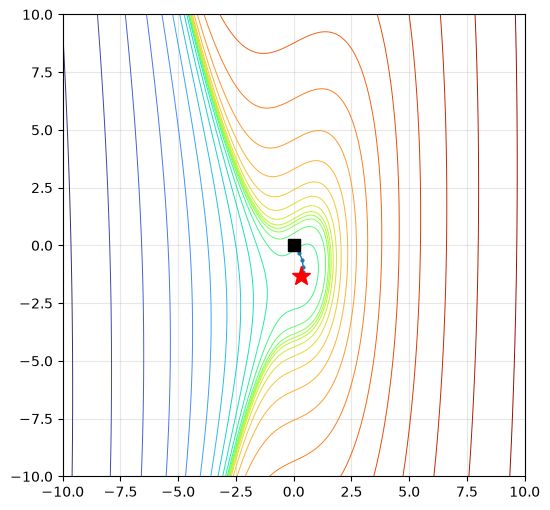

In [18]:
plot_contour(f2, path_f2)

In [19]:
x_f5, f_f5, path_f5 = newton_rafson(f=f5, x0=[0.0, 3.0], limit=100)
plot3d(f5, path_f5, [0,1], x_f5, title="Марквардт на f5", bounds=(-20, 20, -20, 20))
print(f'{path_f5}')

[[ 0.00000000e+00  3.00000000e+00]
 [-6.22389457e-02  2.05779803e+00]
 [-1.03178183e-01  1.47195305e+00]
 [-1.03365451e-01  1.15297487e+00]
 [-5.40491261e-02  1.03014325e+00]
 [-8.80418463e-03  1.00346143e+00]
 [-2.03398628e-04  1.00008369e+00]
 [-5.19656267e-07  9.99999715e-01]]


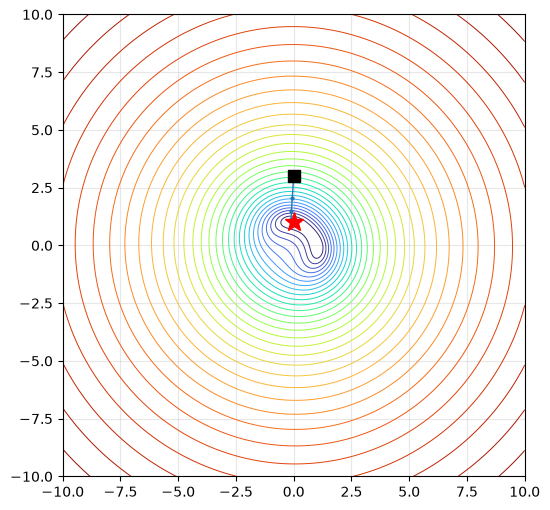

In [20]:
plot_contour(f5, path_f5)

In [21]:
x_f5, f_f5, path_f5 = newton_rafson(f=f5, x0=[3.0, 0.0], limit=100)
plot3d(f5, path_f5, [1,0], x_f5, title="Марквардт на f5", bounds=(-20, 20, -20, 20))
print(f'{path_f5}')

[[ 3.00000000e+00  0.00000000e+00]
 [ 2.05779803e+00 -6.22389457e-02]
 [ 1.47195078e+00 -1.03186437e-01]
 [ 1.15297438e+00 -1.03368529e-01]
 [ 1.03014320e+00 -5.40500704e-02]
 [ 1.00346148e+00 -8.80430429e-03]
 [ 1.00008369e+00 -2.03404639e-04]
 [ 9.99999715e-01 -5.19656664e-07]]


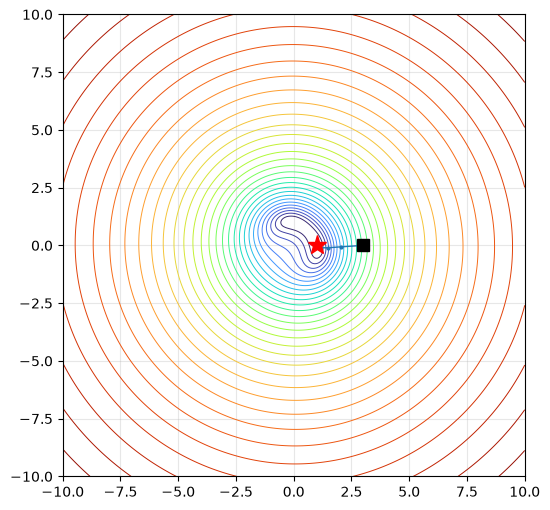

In [22]:
plot_contour(f5, path_f5)